# Lecture 17

Today's Topics:

- Transfer Learning
- Pretrained Models in torchvision
- Baseline vs Pretrained
- Feature Extraction
- Fine-Tuning

In [1]:
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from torchvision.models import resnet18, ResNet18_Weights

print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

PyTorch version: 2.15.0+cu132
torchvision version: 0.29.2+cu132


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'


### Helper functions

These are the same `train_step()`, `test_step()`, `fit()` (with early stopping) and `plot_history()` functions from last lecture.

In [3]:
BATCH_SIZE = 32

def accuracy_fn(y_true, y_pred):
    # Calculates accuracy (as a percentage) between truth labels and predictions
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100


def train_step(model, data_loader, loss_fn, optimizer, accuracy_fn, device=device):
    train_loss, train_acc = 0, 0
    model.to(device)
    model.train()
    for X, y in data_loader:
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return train_loss / len(data_loader), train_acc / len(data_loader)


def test_step(model, data_loader, loss_fn, accuracy_fn, device=device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            test_pred = model(X)
            test_loss += loss_fn(test_pred, y).item()
            test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))
    return test_loss / len(data_loader), test_acc / len(data_loader)

In [4]:
def fit(model, train_dataloader, val_dataloader, loss_fn, optimizer,
        epochs, patience=None, print_every=1, device=device):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, accuracy_fn, device)
        val_loss, val_acc = test_step(model, val_dataloader, loss_fn, accuracy_fn, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if epoch % print_every == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:2d} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% "
                  f"| Val loss: {val_loss:.4f}, acc: {val_acc:.2f}%")

        if patience is not None:
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= patience:
                    print(f"Stopping early at epoch {epoch}: no improvement for {patience} epochs.")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"Restored model from epoch {best_epoch} (val loss {best_val_loss:.4f}, "
              f"val acc {history['val_acc'][best_epoch]:.2f}%)")
        history["best_epoch"] = best_epoch
    return history


def plot_history(histories: dict, title=""):
    # Plots train (dashed) and validation (solid) curves for one or more models
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for i, (name, h) in enumerate(histories.items()):
        color = f"C{i}"
        epochs = range(1, len(h["train_loss"]) + 1)
        axes[0].plot(epochs, h["train_loss"], "--", color=color, label=f"{name} (train)")
        axes[0].plot(epochs, h["val_loss"], "-", color=color, label=f"{name} (val)")
        axes[1].plot(epochs, h["train_acc"], "--", color=color, label=f"{name} (train)")
        axes[1].plot(epochs, h["val_acc"], "-", color=color, label=f"{name} (val)")
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Why Transfer Learning

At the end of last lecture, our TinyVGG CNN reached about 89% on FashionMNIST, and its loss curves suggested it was underfitting since the train and validation loss tracked each other closely. The next step is a bigger model.

But bigger models have a cost. A model with millions of parameters needs a lot of data to train without overfitting and a lot of compute. 

**Transfer learning** gets around this: take a model that someone else already trained on a huge dataset, and reuse what it learned for *your* problem.

Why should that work? A CNN learns in layers:

- **Early layers** learn very general features: edges, corners, color blobs, simple textures.
- **Middle layers** combine those into patterns: fur, wheels, eyes, stripes.
- **Late layers** combine those into features specific to the original task's categories.

Edges and textures are useful for almost any image problem. So we can keep the early and middle layers, and only replace (or lightly adjust) the parts that are specific to the original task.

This is the same idea as our LLM lecture: GPT-2 and the Ollama models were trained once on huge amounts of text, and we reused them. Today we do it with images, and we'll see how to adapt the pretrained model to our own task.

## Pretrained Models in torchvision

`torchvision.models` contains many architectures, each with weights pretrained on **ImageNet**: about 1.28 million photos in 1,000 categories. We'll use **ResNet-18**, a CNN with 18 layers. It's built from the same pieces as TinyVGG (convolutions, ReLU, pooling), plus two additions that make deep networks easier to train: *batch normalization* and *skip connections*.

Each model comes with a `weights` object that holds the pretrained parameters and information about how they were trained. The first time you run this code, PyTorch downloads the weights (about 45 MB) and caches them.

In [5]:
weights = ResNet18_Weights.DEFAULT   # the best available pretrained weights
pretrained_model = resnet18(weights=weights).to(device)

total_params = sum(p.numel() for p in pretrained_model.parameters())
print(f"ResNet-18 parameters: {total_params:,}")

ResNet-18 parameters: 11,689,512


For comparison, last lecture's TinyVGG had about 7,700 parameters. ResNet-18 has over 11 million.

A model is made of named sub-modules. Let's list the top-level ones and how many parameters each holds:

In [6]:
for name, child in pretrained_model.named_children():
    n_params = sum(p.numel() for p in child.parameters())
    print(f"{name:10s} {n_params:>12,}   {child.__class__.__name__}")

conv1             9,408   Conv2d
bn1                 128   BatchNorm2d
relu                  0   ReLU
maxpool               0   MaxPool2d
layer1          147,968   Sequential
layer2          525,568   Sequential
layer3        2,099,712   Sequential
layer4        8,393,728   Sequential
avgpool               0   AdaptiveAvgPool2d
fc              513,000   Linear


- `conv1`, `bn1`, `relu`, `maxpool`: the "stem", which processes the raw image.
- `layer1` to `layer4`: four groups of convolutional blocks. Early layers have few channels; `layer4` has 512 channels and holds most of the parameters.
- `avgpool`: averages each of the 512 channels over the whole image, giving one vector of 512 numbers per image.
- `fc`: the final fully connected layer, the **classifier head**.

Everything before `fc` is often called the **backbone**. Its job is to turn an image into a useful 512-number description. The head's job is to turn that description into class scores. Let's look at the head:

In [7]:
pretrained_model.fc

Linear(in_features=512, out_features=1000, bias=True)

512 inputs, 1,000 outputs: one logit for each ImageNet category. The category names are stored in the weights object:

In [8]:
imagenet_categories = weights.meta["categories"]
print(len(imagenet_categories))
print(imagenet_categories[:10])
print(imagenet_categories[281:286])

1000
['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich']
['tabby', 'tiger cat', 'Persian cat', 'Siamese cat', 'Egyptian cat']


ImageNet has some very specific categories: five kinds of cat, over 100 dog breeds, and many objects. The weights object also records how well the model does on ImageNet:

In [9]:
weights.meta["_metrics"]

{'ImageNet-1K': {'acc@1': 69.758, 'acc@5': 89.078}}

About 70% top-1 accuracy (the top guess is right) and 89% top-5 accuracy (the right answer is among the top 5 guesses), across 1,000 categories.

## What a Pretrained Model Already Knows

### The first layer's filters

Remember from our vision lecture that a convolutional layer is a set of small filters slid across the image. ResNet-18's first layer has 64 filters, each 7x7 pixels with 3 color channels, so we can display them as tiny color images.

Let's compare the filters of the pretrained model with those of an untrained model (random weights):

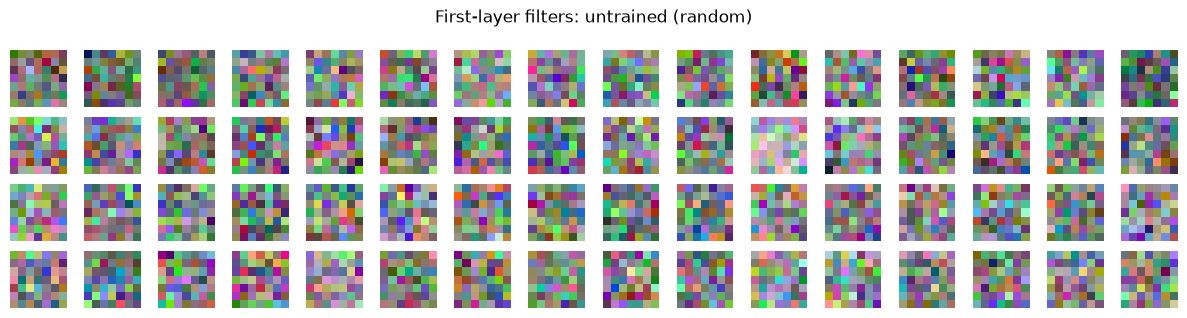

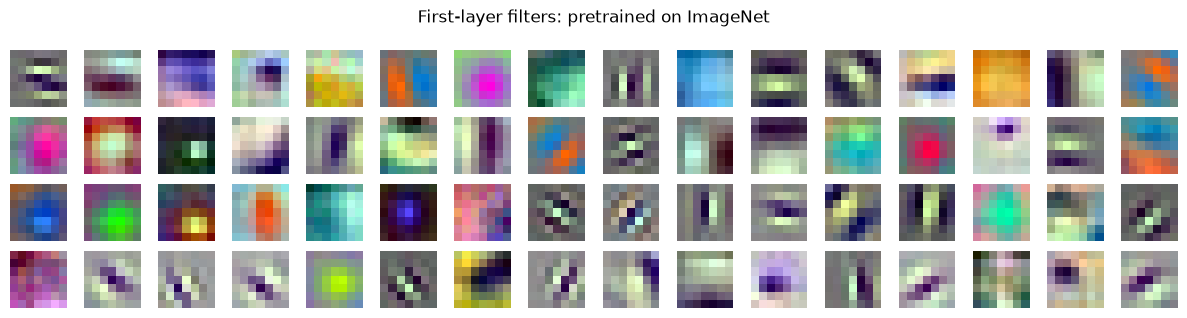

In [10]:
def show_filters(conv_weight, title):
    # conv_weight has shape [64, 3, 7, 7]: 64 filters, 3 color channels, 7x7 pixels
    w = conv_weight.detach().cpu().clone()
    fig, axes = plt.subplots(4, 16, figsize=(12, 3.2))
    for i, ax in enumerate(axes.flat):
        f = w[i]
        f = (f - f.min()) / (f.max() - f.min())   # rescale to [0, 1] for display
        ax.imshow(f.permute(1, 2, 0))              # [C, H, W] -> [H, W, C]
        ax.axis(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

untrained_model = resnet18(weights=None)

show_filters(untrained_model.conv1.weight, "First-layer filters: untrained (random)")
show_filters(pretrained_model.conv1.weight, "First-layer filters: pretrained on ImageNet")

The untrained filters are random noise. The pretrained filters have clear structure:

- **Edge and line detectors** at different angles: horizontal, vertical and diagonal bars, light on one side and dark on the other.
- **Color blobs**: a spot of one color (magenta, green, blue, red) on a neutral background.
- **Color contrasts**: one color on one side and another on the other, such as orange against blue.

Nobody manually programmed these filters, instead the network learned them because they were useful for classifying ImageNet photos, and they're useful for almost any other image task too. This is what we borrow.

### CIFAR-10

**CIFAR-10** has 60,000 small color images (32x32 pixels) in 10 classes. Unlike FashionMNIST, these are real photos, much closer to what ImageNet models were trained on. It's built into torchvision.

First, let's load it with just `ToTensor()` so we can look at the images:

In [11]:
raw_train_data = datasets.CIFAR10(root="data", train=True, download=True, transform=ToTensor())
raw_test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=ToTensor())

class_names = raw_train_data.classes
print(len(raw_train_data), len(raw_test_data))
class_names

50000 10000


['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

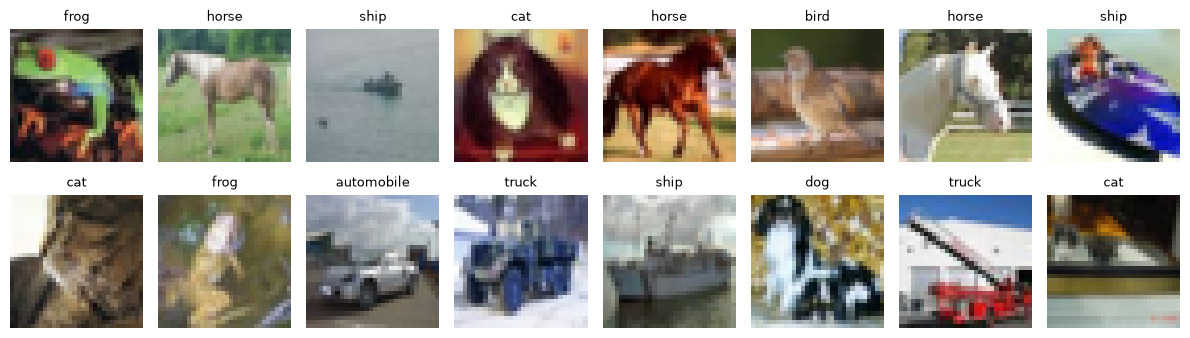

In [12]:
torch.manual_seed(42)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax in axes.flat:
    i = torch.randint(0, len(raw_train_data), size=[1]).item()
    img, label = raw_train_data[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[label], fontsize=9)
    ax.axis(False)
plt.tight_layout()
plt.show()

### Asking ImageNet's 

Before changing anything, let's see what the pretrained model says about some CIFAR-10 test images, using its original 1,000-category head. We need to prepare the images the way the model expects; we'll explain these steps in the next section.

The model outputs **logits**; `torch.softmax()` turns them into probabilities, and `topk()` picks the 3 most likely categories.

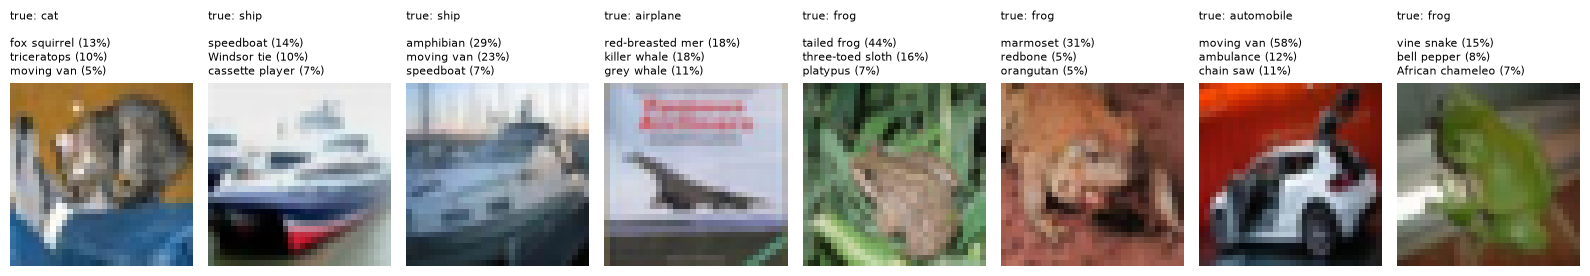

In [13]:
demo_transform = weights.transforms()   # the preprocessing used to train the model
demo_data = datasets.CIFAR10(root="data", train=False, download=True, transform=demo_transform)

demo_idx = list(range(8))
X_demo = torch.stack([demo_data[i][0] for i in demo_idx]).to(device)

pretrained_model.eval()
with torch.inference_mode():
    probs = torch.softmax(pretrained_model(X_demo), dim=1)
top_probs, top_classes = probs.topk(3, dim=1)

fig, axes = plt.subplots(1, 8, figsize=(16, 3.8))
for ax, i, p, c in zip(axes, demo_idx, top_probs.cpu(), top_classes.cpu()):
    img, label = raw_test_data[i]
    ax.imshow(img.permute(1, 2, 0))
    guesses = "\n".join(f"{imagenet_categories[int(k)][:16]} ({100*pk:.0f}%)" for pk, k in zip(p, c))
    ax.set_title(f"true: {class_names[label]}\n\n{guesses}", fontsize=8, loc="left")
    ax.axis(False)
plt.tight_layout()
plt.show()

The results are mixed, and the model isn't confident: its top guess is below 50% for all but one image.

- **Right neighborhood**: the ships become "speedboat" and "amphibian", the car becomes "moving van" and "ambulance", one frog is correctly a "tailed frog", and the green frog becomes "vine snake" and "African chameleon", other small green animals.
- **Way off**: the cat is a "fox squirrel" and the airplane is a "red-breasted merganser" or a "killer whale". Look at the airplane picture, though: a long pointed shape against a pale background really does resemble a diving bird or a whale.

Remember that these images are 32x32 pixels blown up to 224x224, much blurrier than anything the model was trained on.

More importantly, the categories don't match ours. ImageNet has no plain "automobile" or "dog" class; it has "sports car", "moving van", "golden retriever", and so on. So we'll keep the backbone, which knows how to describe an image, and give the model a **new head** that maps that description to our 10 classes.

## Preparing Data for a Pretrained Model

A pretrained model expects its inputs to look like the data it was trained on. Let's see how ImageNet models expect images to be prepared:

In [14]:
weights.transforms()

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

Two things matter:

1. **Size.** The model was trained on 224x224 images. Convolutions work on any size image, so we can use a different size, but features work best at a scale similar to training. Larger images are also slower. As a compromise, we'll resize our 32x32 images to **128x128**.
2. **Normalization.** Each color channel was standardized using the ImageNet mean and standard deviation: $x_{\text{norm}} = (x - \text{mean}) / \text{std}$. We must use **the same numbers**, otherwise the model sees inputs on a scale it has never seen, and its learned filters respond in the wrong way. This is the same reason you apply a training set's `StandardScaler` to the test set rather than fitting a new one.

We'll use a little augmentation (random horizontal flips) on the training set only.

In [15]:
IMG_SIZE = 128
mean, std = weights.transforms().mean, weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

train_data_augmented = datasets.CIFAR10(root="data", train=True, download=True, transform=train_transform)
train_data_eval = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)

### A small-data setting

Transfer learning matters most when you *don't* have much labeled data. So we'll pretend we only have **2,000 labeled training images**, plus 2,000 for validation. The test set is the full 10,000 CIFAR-10 test images, which we'll use once at the end.

We shuffle the indices once and split them. The validation subset uses the dataset *without* augmentation.

In [16]:
N_TRAIN, N_VAL = 2_000, 2_000

perm = torch.randperm(len(train_data_eval), generator=torch.Generator().manual_seed(42))
train_idx = perm[:N_TRAIN].tolist()
val_idx = perm[N_TRAIN:N_TRAIN + N_VAL].tolist()

train_subset = Subset(train_data_augmented, train_idx)
val_subset = Subset(train_data_eval, val_idx)

train_dataloader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

X_batch, y_batch = next(iter(train_dataloader))
print(f"Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_data)}")
print(f"One batch: {X_batch.shape}")

Train: 2000 | Val: 2000 | Test: 10000
One batch: torch.Size([32, 3, 128, 128])


## Baseline: Training from Scratch

To see what pretraining buys us, we need a baseline: the **same architecture** trained from random weights on our 2,000 images. The only difference between this and the next experiments will be where the starting weights come from.

To adapt ResNet-18 to 10 classes, we replace its `fc` layer with a new `nn.Linear(512, 10)`. `model.fc.in_features` gives us the 512 so we don't have to hard-code it.

In [ ]:
def make_resnet(pretrained: bool, num_classes: int = 10):
    # ResNet-18 with a new head for our classes.
    # pretrained=True loads ImageNet weights; pretrained=False starts from random weights.
    model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
    model.fc = nn.Linear(in_features=model.fc.in_features, out_features=num_classes)
    return model


def restored_val_acc(history):
    # Validation accuracy of the epoch that fit() restored (lowest validation loss)
    return history["val_acc"][history.get("best_epoch", -1)]


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total

loss_fn = nn.CrossEntropyLoss()
training_time = {}   # we'll record how long each approach takes

In [ ]:
scratch_model = make_resnet(pretrained=False).to(device)
trainable, total = count_params(scratch_model)
print(f"Trainable parameters: {trainable:,} of {total:,}\n")

optimizer = torch.optim.Adam(scratch_model.parameters(), lr=0.001)

start = time.time()
scratch_history = fit(scratch_model, train_dataloader, val_dataloader, loss_fn, optimizer,
                      epochs=10, patience=3)
training_time["from scratch"] = time.time() - start
print(f"\nTraining time: {training_time['from scratch'] / 60:.1f} min")

Trainable parameters: 11,181,642 of 11,181,642

Epoch  0 | Train loss: 1.9981, acc: 27.93% | Val loss: 1.9221, acc: 33.23%
Epoch  1 | Train loss: 1.7010, acc: 37.70% | Val loss: 1.8033, acc: 36.01%
Epoch  2 | Train loss: 1.6020, acc: 41.67% | Val loss: 1.6713, acc: 39.73%
Epoch  3 | Train loss: 1.4248, acc: 46.88% | Val loss: 1.8562, acc: 36.90%
Epoch  4 | Train loss: 1.3978, acc: 47.87% | Val loss: 1.6508, acc: 41.32%
Epoch  5 | Train loss: 1.3053, acc: 52.48% | Val loss: 1.6465, acc: 44.05%
Epoch  6 | Train loss: 1.1941, acc: 55.36% | Val loss: 1.8248, acc: 44.74%
Epoch  7 | Train loss: 1.0911, acc: 60.71% | Val loss: 1.6379, acc: 44.89%
Epoch  8 | Train loss: 1.0079, acc: 63.39% | Val loss: 1.6063, acc: 44.79%
Epoch  9 | Train loss: 0.8746, acc: 67.76% | Val loss: 1.7404, acc: 47.87%
Restored model from epoch 8 (val loss 1.6063, val acc 44.79%)

Training time: 1.8 min


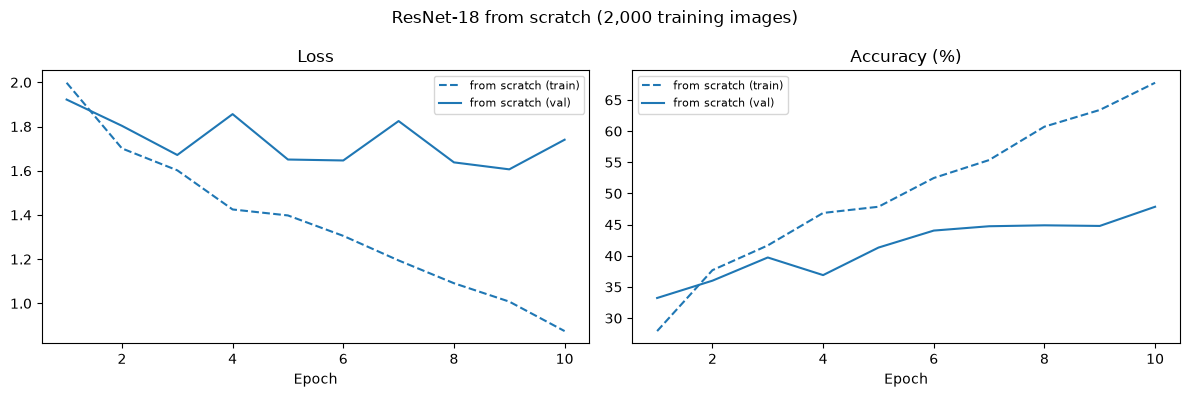

In [19]:
plot_history({"from scratch": scratch_history}, title="ResNet-18 from scratch (2,000 training images)")

- Training accuracy keeps climbing (68% by the last epoch), but validation accuracy stalls in the 40s. Early stopping restored epoch 8, at **44.8%** validation accuracy.
- Validation loss is jumpy and barely improves after the first few epochs, while training loss keeps falling: the widening gap is the overfitting signature from Lecture 16.

That's better than guessing (10%), but not by much for a model this size. Training a large network from scratch needs far more data than we have. Now let's start from pretrained weights instead.

## Feature Extraction (aka Freezing the Backbone)

The simplest form of transfer learning:

1. Load the pretrained model.
2. **Freeze** the backbone, so its weights don't change during training.
3. Replace the head and train **only the head**.

Freezing is done by turning off gradients. Every parameter has a `requires_grad` attribute; when it's `False`, `loss.backward()` doesn't compute a gradient for it, and the optimizer has nothing to update.

In [20]:
torch.manual_seed(42)
fe_model = make_resnet(pretrained=True)

# 1. Freeze everything
for param in fe_model.parameters():
    param.requires_grad = False

# 2. Unfreeze the new head
for param in fe_model.fc.parameters():
    param.requires_grad = True

fe_model = fe_model.to(device)
trainable, total = count_params(fe_model)
print(f"Trainable parameters: {trainable:,} of {total:,} ({100 * trainable / total:.2f}%)")

Trainable parameters: 5,130 of 11,181,642 (0.05%)


Only 5,130 parameters are trainable: the new `fc` layer's $512 \times 10$ weights plus 10 biases. That's fewer than TinyVGG's ~7,700.

We only give the optimizer the parameters we want to train:

In [21]:
optimizer = torch.optim.Adam(fe_model.fc.parameters(), lr=0.001)

start = time.time()
fe_history = fit(fe_model, train_dataloader, val_dataloader, loss_fn, optimizer,
                 epochs=8, patience=3)
training_time["feature extraction"] = time.time() - start
print(f"\nTraining time: {training_time['feature extraction'] / 60:.1f} min")

Epoch  0 | Train loss: 1.6851, acc: 44.00% | Val loss: 1.1416, acc: 64.78%
Epoch  1 | Train loss: 1.0170, acc: 69.39% | Val loss: 0.8900, acc: 72.12%
Epoch  2 | Train loss: 0.8592, acc: 74.31% | Val loss: 0.8019, acc: 74.85%
Epoch  3 | Train loss: 0.7106, acc: 78.77% | Val loss: 0.7740, acc: 74.40%
Epoch  4 | Train loss: 0.7077, acc: 76.98% | Val loss: 0.7537, acc: 74.36%
Epoch  5 | Train loss: 0.6547, acc: 78.87% | Val loss: 0.7356, acc: 74.45%
Epoch  6 | Train loss: 0.6210, acc: 80.36% | Val loss: 0.7105, acc: 76.09%
Epoch  7 | Train loss: 0.6033, acc: 80.56% | Val loss: 0.6960, acc: 75.60%
Restored model from epoch 7 (val loss 0.6960, val acc 75.60%)

Training time: 0.7 min


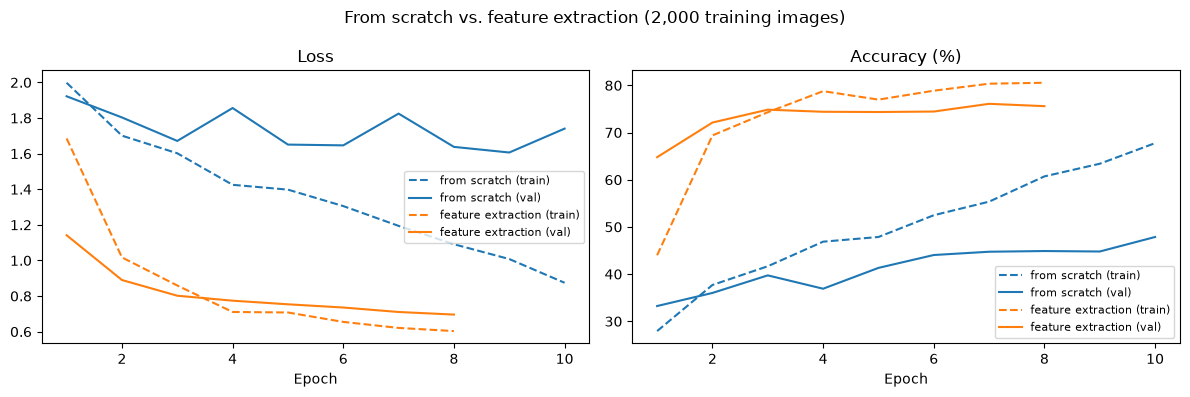

In [22]:
plot_history({"from scratch": scratch_history, "feature extraction": fe_history},
             title="From scratch vs. feature extraction (2,000 training images)")

Compare the two models:

- **Validation accuracy**: feature extraction reached **75.6%**, against 44.8% from scratch, even though it trained 5,130 parameters instead of 11 million.
- **First epoch**: after a single epoch, the pretrained model was already at 64.8% validation accuracy, far above anything the from-scratch model reached in 10 epochs. The backbone already produces useful features; the head only has to learn which features go with which class.
- **Overfitting**: with so few trainable parameters, the model has little room to memorize. Its train and validation curves stay close together.
- **Speed**: about 0.9 minutes vs. 2.2 minutes, because no gradients are computed for the backbone.

You may notice that the feature-extraction model's *training* accuracy is lower than its validation accuracy in the first epochs. That's normal: training accuracy is averaged over the epoch while the model is still learning, and it's measured on augmented images.

## Features as Data

Here's another way to look at feature extraction. If the backbone never changes, then each image always produces the same 512 numbers. We can compute those numbers **once**, then treat them as an ordinary table of data, with one row per image and 512 feature columns.

To get the features, we replace the head with `nn.Identity()`, a layer that returns its input unchanged. The model then outputs the 512-number description instead of class scores. These descriptions are often called **embeddings**, the same word we used for text in Lecture 15.

In [23]:
feature_extractor = resnet18(weights=weights)
feature_extractor.fc = nn.Identity()   # output the 512 features instead of 1,000 logits


def extract_features(model, dataset, batch_size=64):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    model.to(device)
    model.eval()   # eval mode: batch norm uses its stored averages, so the backbone is truly fixed
    features, labels = [], []
    with torch.inference_mode():
        for X, y in loader:
            features.append(model(X.to(device)).cpu())
            labels.append(y)
    return torch.cat(features).numpy(), torch.cat(labels).numpy()


start = time.time()
X_train_feat, y_train = extract_features(feature_extractor, Subset(train_data_eval, train_idx))  # no augmentation
X_val_feat, y_val = extract_features(feature_extractor, val_subset)
print(f"Extracted features in {time.time() - start:.0f} s")
print(X_train_feat.shape, X_val_feat.shape)

Extracted features in 7 s
(2000, 512) (2000, 512)


Now we have a plain 2,000 x 512 array. Any model from earlier in the course can use it. Let's try **logistic regression**.

As a comparison, we'll also run logistic regression on the **raw pixels**: each 32x32x3 image flattened into 3,072 numbers.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def pixels(dataset, indices):
    # Flatten each 32x32x3 image into a row of 3,072 numbers
    return np.stack([dataset[i][0].flatten().numpy() for i in indices])

X_train_pix, X_val_pix = pixels(raw_train_data, train_idx), pixels(raw_train_data, val_idx)

start = time.time()
logreg_pixels = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logreg_pixels.fit(X_train_pix, y_train)
pixel_acc = logreg_pixels.score(X_val_pix, y_val) * 100

logreg_features = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logreg_features.fit(X_train_feat, y_train)
feature_acc = logreg_features.score(X_val_feat, y_val) * 100
training_time["features + logistic regression"] = time.time() - start

print(f"Logistic regression on raw pixels:          {pixel_acc:.2f}% val accuracy")
print(f"Logistic regression on ResNet-18 features:  {feature_acc:.2f}% val accuracy")

Logistic regression on raw pixels:          27.65% val accuracy
Logistic regression on ResNet-18 features:  80.15% val accuracy


Same algorithm, same images: **27.7%** on raw pixels vs. **80.2%** on pretrained features. The only difference is the representation.

This is really what the frozen ResNet in the previous section was doing. A frozen backbone plus one `nn.Linear` layer trained with cross-entropy loss *is* (multi-class) logistic regression on the features.

So why did logistic regression score higher than the frozen ResNet (80.2% vs. 75.6%)? Look back at the feature-extraction training log: validation loss went down in *every* epoch, and early stopping never triggered. The head simply hadn't finished training after 8 epochs, while scikit-learn's `LogisticRegression` runs until it converges. The augmentation and the batch-norm drift mentioned above also make the two setups slightly different. Training the head for more epochs would close most of the gap.

### Seeing the difference

We can't plot 512 dimensions, but we can squash them into 2 with a dimensionality reduction tool like PCA, or in this case, **t-SNE**, a method that places points so that images with similar features end up near each other. Let's compare the validation images as raw pixels vs. as ResNet features:

t-SNE took 4 s


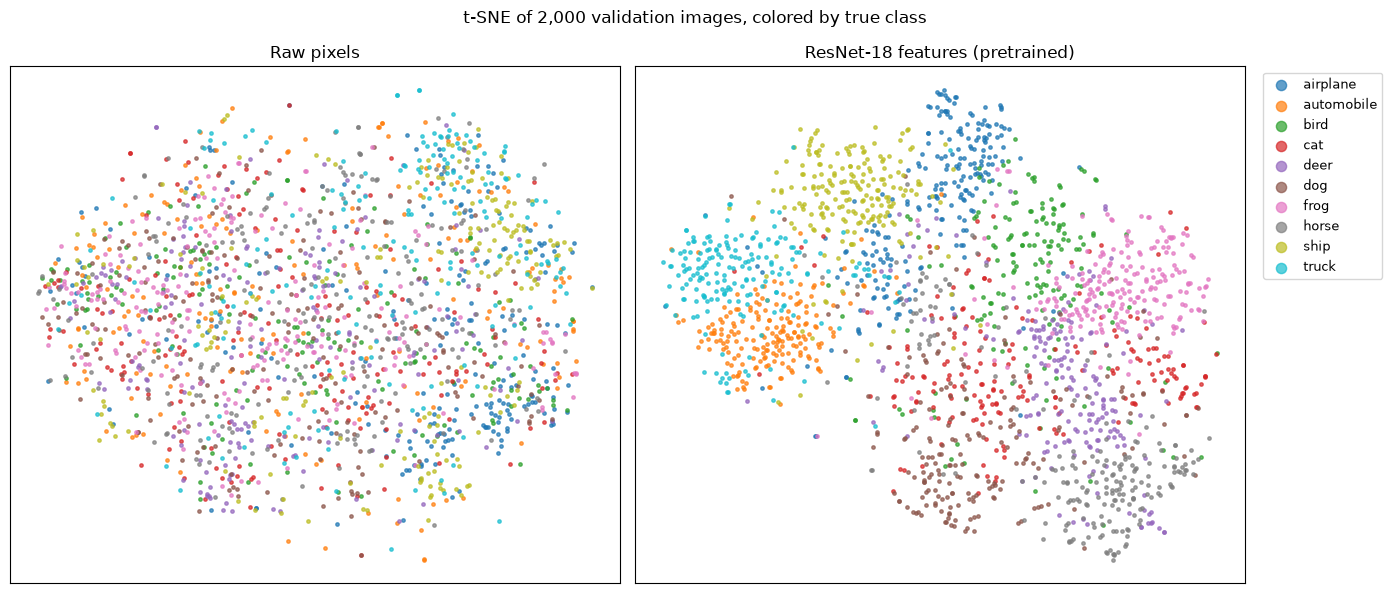

In [25]:
from sklearn.manifold import TSNE

start = time.time()
pix_2d = TSNE(n_components=2, init="pca", random_state=42).fit_transform(X_val_pix)
feat_2d = TSNE(n_components=2, init="pca", random_state=42).fit_transform(X_val_feat)
print(f"t-SNE took {time.time() - start:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, points, title in [(axes[0], pix_2d, "Raw pixels"),
                          (axes[1], feat_2d, "ResNet-18 features (pretrained)")]:
    for k, name in enumerate(class_names):
        mask = y_val == k
        ax.scatter(points[mask, 0], points[mask, 1], s=6, alpha=0.7, color=plt.cm.tab10(k), label=name)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("t-SNE of 2,000 validation images, colored by true class")
plt.tight_layout()
plt.show()

In pixel space, the classes are almost completely mixed together. Two images are "close" when their colors and brightness are similar, regardless of what's in them. The little structure there is comes from backgrounds: ships, airplanes and trucks drift toward one edge, because blue sky and blue water look alike to a pixel comparison.

In feature space, images of the same class form clusters, which is exactly what makes a simple linear classifier work well on top. The layout is meaningful too:

- **Vehicles** sit together on one side: truck next to automobile, ship next to airplane.
- **Animals** sit on the other side, and they overlap much more: cat and dog are mixed together, and so are deer and horse.

Those overlapping pairs are the ones we should expect the model to confuse.

### How much data do we need?

Because training on features is so fast, we can easily ask: how does accuracy change with the number of labeled images?

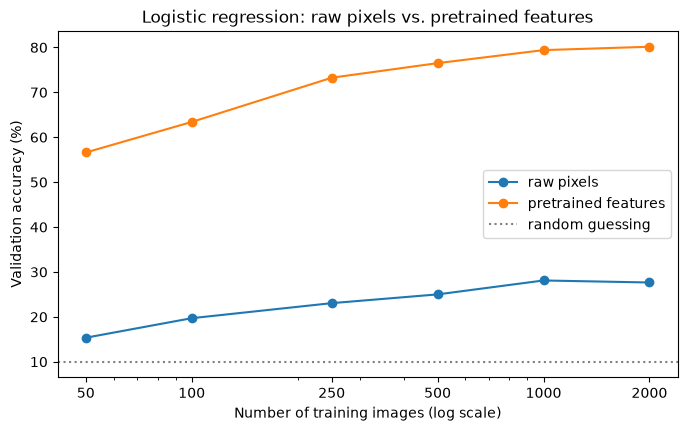

,raw pixels,pretrained features
training images,,
50,15.4,56.6
100,19.7,63.4
250,23.0,73.2
500,25.0,76.5
1000,28.1,79.4
2000,27.6,80.2


In [26]:
sizes = [50, 100, 250, 500, 1000, 2000]
curve = {"raw pixels": [], "pretrained features": []}

for n in sizes:
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train_pix[:n], y_train[:n])
    curve["raw pixels"].append(m.score(X_val_pix, y_val) * 100)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train_feat[:n], y_train[:n])
    curve["pretrained features"].append(m.score(X_val_feat, y_val) * 100)

plt.figure(figsize=(8, 4.5))
for name, accs in curve.items():
    plt.plot(sizes, accs, "o-", label=name)
plt.axhline(10, color="gray", linestyle=":", label="random guessing")
plt.xscale("log")
plt.xticks(sizes, [str(s) for s in sizes])
plt.xlabel("Number of training images (log scale)")
plt.ylabel("Validation accuracy (%)")
plt.title("Logistic regression: raw pixels vs. pretrained features")
plt.legend()
plt.show()

pd.DataFrame(curve, index=pd.Index(sizes, name="training images")).round(1)

- With pretrained features, **50 labeled images** (5 per class) reach 56.6%, already about double what raw pixels reach with **2,000** images (27.6%).
- With pretrained features, 250 images reach 73%, and the curve flattens out after about 1,000 images.
- Raw pixels improve slowly and stop improving at around 28%: a linear model on pixels just can't represent what makes a cat a cat.

This is the main practical benefit of transfer learning: **it substitutes for labeled data you don't have**.

## Fine-Tuning

Feature extraction uses the backbone exactly as ImageNet left it. But our images are different from ImageNet's: tiny, blurry, upscaled photos. The general early-layer features (edges, colors) should still apply, but the later, more specialized layers might be better if they adjusted a little to our data.

**Fine-tuning** unfreezes some of the backbone, usually the last layers, and keeps training. We'll unfreeze `layer4`, the last convolutional block.

Two rules of thumb make fine-tuning work:

1. **Train the head first.** A brand-new head has random weights and produces large, noisy gradients. If the backbone is unfrozen from the start, those gradients can wreck the pretrained features before the head has learned anything. So we start from our feature-extraction model, whose head is already trained.
2. **Use a small learning rate.** We want to *adjust* the pretrained weights, not overwrite them. A learning rate 10x smaller than usual is a common choice.

In [27]:
ft_model = copy.deepcopy(fe_model)   # start from the trained feature-extraction model

for param in ft_model.layer4.parameters():
    param.requires_grad = True

trainable, total = count_params(ft_model)
print(f"Trainable parameters: {trainable:,} of {total:,} ({100 * trainable / total:.1f}%)")

Trainable parameters: 8,398,858 of 11,181,642 (75.1%)


`layer4` holds most of the network's parameters, so we're now training about 8 million of them. The optimizer can take **parameter groups**, each with its own settings, so we could give different parts of the model different learning rates. Here we give both groups the same small learning rate, `1e-4`.

In [28]:
optimizer = torch.optim.Adam([
    {"params": ft_model.layer4.parameters(), "lr": 1e-4},
    {"params": ft_model.fc.parameters(), "lr": 1e-4},
])

start = time.time()
ft_history = fit(ft_model, train_dataloader, val_dataloader, loss_fn, optimizer,
                 epochs=6, patience=2)
training_time["fine-tuning"] = time.time() - start + training_time["feature extraction"]  # includes training the head first
print(f"\nTraining time (this stage): {(time.time() - start) / 60:.1f} min")

Epoch  0 | Train loss: 0.5302, acc: 81.65% | Val loss: 0.5527, acc: 80.70%
Epoch  1 | Train loss: 0.1957, acc: 94.30% | Val loss: 0.5070, acc: 81.45%
Epoch  2 | Train loss: 0.1079, acc: 97.57% | Val loss: 0.5133, acc: 82.44%
Epoch  3 | Train loss: 0.0729, acc: 98.31% | Val loss: 0.5076, acc: 82.84%
Stopping early at epoch 3: no improvement for 2 epochs.
Restored model from epoch 1 (val loss 0.5070, val acc 81.45%)

Training time (this stage): 0.6 min


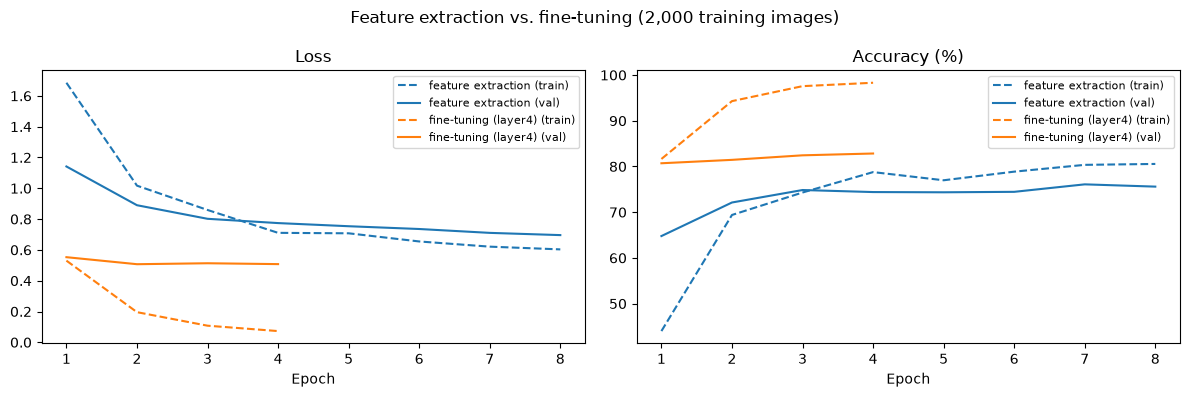

In [29]:
plot_history({"feature extraction": fe_history, "fine-tuning (layer4)": ft_history},
             title="Feature extraction vs. fine-tuning (2,000 training images)")

- Fine-tuning started at 80.7% validation accuracy in its first epoch, above where feature extraction ended (75.6%). Letting `layer4` adapt to our images helped right away.
- It also **overfit very quickly**. Training accuracy jumped from 82% to 98% in three epochs while validation accuracy crept from 81% to 83%. With 8 million trainable parameters and 2,000 images, the model can memorize the training set in a few passes.
- Early stopping restored **epoch 1 (81.45%)**, even though validation *accuracy* kept rising to 82.84% at epoch 3. That's because `fit()` stops on validation *loss*, which flattened after epoch 1. Loss and accuracy can disagree: as the model memorizes the training set, it becomes more confident, and confident wrong answers raise the loss even while a few more answers become right. Stopping on loss is the more cautious choice; stopping on accuracy would have kept a slightly better model here.

Whether fine-tuning beats feature extraction depends on how much data you have and how different it is from the pretraining data. Here it gained about 1-2 points over logistic regression on the frozen features, for a lot more computation and much more overfitting risk.

## Comparing the Approaches

Let's put everything side by side, using **validation** accuracy to compare (the test set is still untouched). For the neural networks, this is the accuracy of the epoch that early stopping restored, i.e. the model we actually have.

In [30]:
results = pd.DataFrame([
    {"approach": "ResNet-18 from scratch",
     "trainable params": count_params(scratch_model)[0],
     "val acc": restored_val_acc(scratch_history),
     "train time (min)": training_time["from scratch"] / 60},
    {"approach": "Feature extraction (frozen backbone)",
     "trainable params": count_params(fe_model)[0],
     "val acc": restored_val_acc(fe_history),
     "train time (min)": training_time["feature extraction"] / 60},
    {"approach": "Pretrained features + logistic regression",
     "trainable params": 512 * 10 + 10,
     "val acc": feature_acc,
     "train time (min)": training_time["features + logistic regression"] / 60},
    {"approach": "Fine-tuning (layer4 + head)",
     "trainable params": count_params(ft_model)[0],
     "val acc": restored_val_acc(ft_history),
     "train time (min)": training_time["fine-tuning"] / 60},
]).set_index("approach")

results.round(2)

,trainable params,val acc,train time (min)
approach,,,
ResNet-18 from scratch,11181642,44.79,1.82
Feature extraction (frozen backbone),5130,75.60,0.74
Pretrained features + logistic regression,5130,80.15,0.56
Fine-tuning (layer4 + head),8398858,81.45,1.31


- The logistic regression time also includes fitting the raw-pixel model (the slower of the two). It doesn't include the few seconds spent extracting features.
- The fine-tuning time includes training the head first, since fine-tuning started from the feature-extraction model.

Fine-tuning has the best validation accuracy, so that's the model we take to the test set.

### Final evaluation on the test set

Let's pick the best model **using validation accuracy**, and evaluate only that model on the test set, once.

In [31]:
candidates = {
    "from scratch": (scratch_model, scratch_history),
    "feature extraction": (fe_model, fe_history),
    "fine-tuning": (ft_model, ft_history),
}
best_name = max(candidates, key=lambda name: restored_val_acc(candidates[name][1]))
best_model = candidates[best_name][0]
print(f"Best model on validation: {best_name}")


def predict(model, data_loader):
    # Returns true labels and predicted labels for every example in data_loader
    model.to(device)
    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for X, y in data_loader:
            y_pred.append(model(X.to(device)).argmax(dim=1).cpu())
            y_true.append(y)
    return torch.cat(y_true), torch.cat(y_pred)

y_test_true, y_test_pred = predict(best_model, test_dataloader)
test_acc = accuracy_fn(y_test_true, y_test_pred)
print(f"Test accuracy ({len(test_data):,} images): {test_acc:.2f}%")

Best model on validation: fine-tuning
Test accuracy (10,000 images): 81.87%


### Where does it make mistakes?

A confusion matrix (Lecture 14) shows which classes get mixed up:

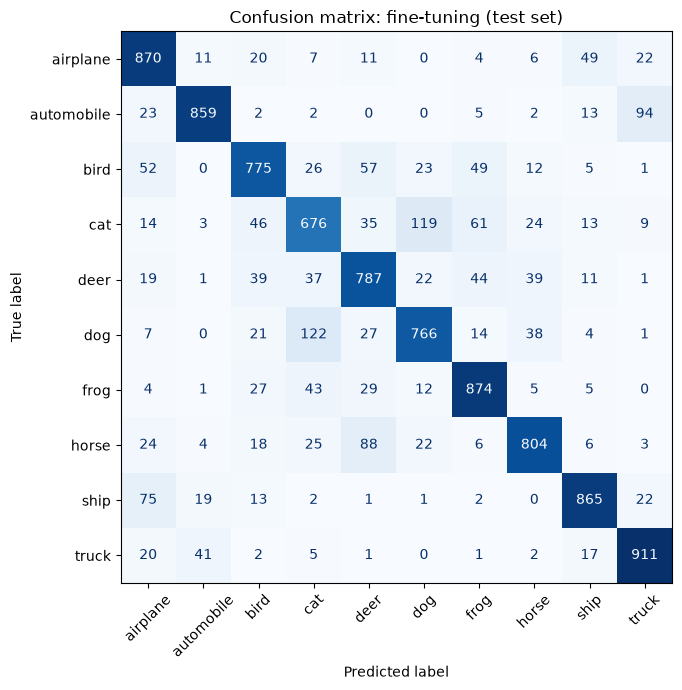

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test_true, y_test_pred, display_labels=class_names,
                                        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"Confusion matrix: {best_name} (test set)")
plt.tight_layout()
plt.show()

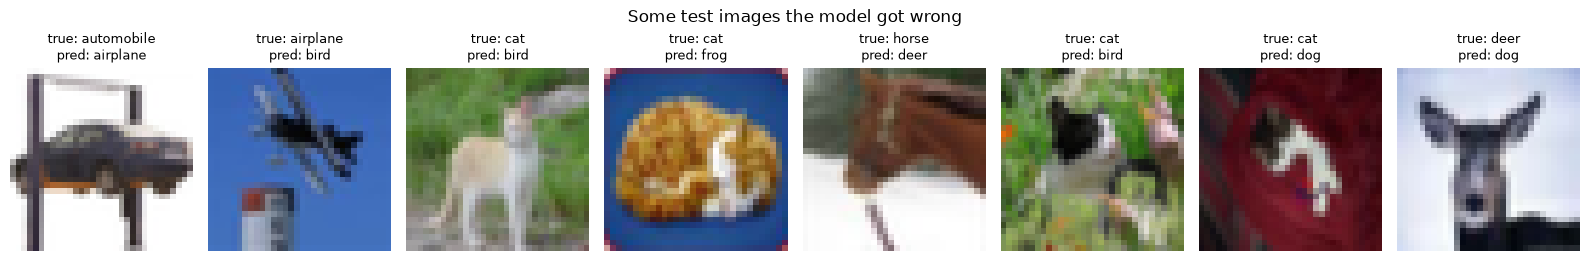

In [33]:
wrong = torch.where(y_test_true != y_test_pred)[0]

torch.manual_seed(42)
sample = wrong[torch.randperm(len(wrong))[:8]]

fig, axes = plt.subplots(1, 8, figsize=(16, 2.8))
for ax, i in zip(axes, sample.tolist()):
    img, label = raw_test_data[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f"true: {class_names[label]}\npred: {class_names[int(y_test_pred[i])]}", fontsize=9)
    ax.axis(False)
fig.suptitle("Some test images the model got wrong")
plt.tight_layout()
plt.show()

The test accuracy, **81.9%**, is close to the validation accuracy (81.5%), so our validation set gave an honest estimate.

The confusion matrix matches the t-SNE plot almost exactly. The biggest mix-ups are the pairs whose clusters overlapped:

- **cat ↔ dog**: 119 cats were called dogs and 122 dogs were called cats. Cat is the hardest class overall (676 of 1,000 correct).
- **automobile → truck**: 94.
- **horse → deer**: 88.
- **ship → airplane**: 75 (blue backgrounds again).

Truck is the easiest class (911 correct).

### Putting it in perspective

| Model | Labeled CIFAR-10 images | Pretrained? | Validation accuracy |
|---|---|---|---|
| ResNet-18 from scratch | 2,000 | No | 44.8% |
| Logistic regression on pretrained features | 2,000 | Yes | 80.2% |
| ResNet-18 fine-tuned | 2,000 | Yes | 81.5% (81.9% on test) |

All three models saw the same 2,000 labeled CIFAR-10 images. The pretrained ones also benefit from 1.28 million *other* labeled images that someone else already paid to collect and train on. That's where the extra 35+ points come from.

## Summary

**Transfer learning** reuses a model trained on a large dataset as the starting point for a new task.

1. **Load a pretrained model** from `torchvision.models` with its `weights`.
2. **Prepare data the way the model expects**: same normalization (mean and std) as pretraining, and a reasonable image size.
3. **Replace the head** with a new layer that outputs your number of classes.
4. **Feature extraction**: freeze the backbone (`requires_grad = False`) and train only the head. Fast, few parameters, hard to overfit. Equivalently, extract features once and use any classifier (e.g., logistic regression).
5. **Fine-tuning**: after training the head, unfreeze the last layers and keep training with a **small learning rate** and early stopping.

Which approach to use depends mostly on how much data you have and how similar it is to the pretraining data:

| Your data | Suggested approach |
|---|---|
| Small, similar to ImageNet (everyday photos) | Feature extraction |
| Small, different from ImageNet (X-rays, satellite images) | Feature extraction first; try fine-tuning the last layers carefully |
| Large, similar to ImageNet | Fine-tune more layers |
| Large, very different | Fine-tune the whole network (pretrained weights are still usually a better start than random) |

The same pattern applies beyond images: the language models from our special lecture are pretrained on huge amounts of text and then fine-tuned or used as feature extractors for specific tasks.